# Progetto Finale: Synthetic Data Sandbox (VAE Edition)

### Struttura del progetto
Questo notebook contiene lo sviluppo completo e l'analisi dei risultati (Fasi 1–4).
Nella Fase 5 il codice viene salvato come moduli Python tramite `%%writefile`
(`data_engine.py`, `vae.py`, `llm_analyst.py`, `api.py`, `app.py`),
perché il backend FastAPI e l'interfaccia Streamlit girano come processi separati.
Per avviare l'applicazione vedi il `README.md`.

## Fase 1: Data Preparation

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import MinMaxScaler, OneHotEncoder

In [2]:
DATASET_URL = (
    "https://raw.githubusercontent.com/jbrownlee/Datasets/master/"
    "pima-indians-diabetes.data.csv"
)

COLUMN_NAMES = [
    "Pregnancies", "Glucose", "BloodPressure", "SkinThickness",
    "Insulin", "BMI", "DiabetesPedigreeFunction", "Age", "Outcome",
]

df = pd.read_csv(DATASET_URL, header=None, names=COLUMN_NAMES)
print("Shape:", df.shape)
df.head()

Shape: (768, 9)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [3]:
df.info()
df.describe().T

<class 'pandas.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


,count,mean,std,min,25%,50%,75%,max
Pregnancies,768.0,3.845052,3.369578,0.000,1.00000,3.0000,6.00000,17.00
Glucose,768.0,120.894531,31.972618,0.000,99.00000,117.0000,140.25000,199.00
BloodPressure,768.0,69.105469,19.355807,0.000,62.00000,72.0000,80.00000,122.00
SkinThickness,768.0,20.536458,15.952218,0.000,0.00000,23.0000,32.00000,99.00
Insulin,768.0,79.799479,115.244002,0.000,0.00000,30.5000,127.25000,846.00
BMI,768.0,31.992578,7.884160,0.000,27.30000,32.0000,36.60000,67.10
DiabetesPedigreeFunction,768.0,0.471876,0.331329,0.078,0.24375,0.3725,0.62625,2.42
Age,768.0,33.240885,11.760232,21.000,24.00000,29.0000,41.00000,81.00
Outcome,768.0,0.348958,0.476951,0.000,0.00000,0.0000,1.00000,1.00


Valori NaN espliciti: 0

Zeri impossibili per colonna:
Glucose            5
BloodPressure     35
SkinThickness    227
Insulin          374
BMI               11
dtype: int64


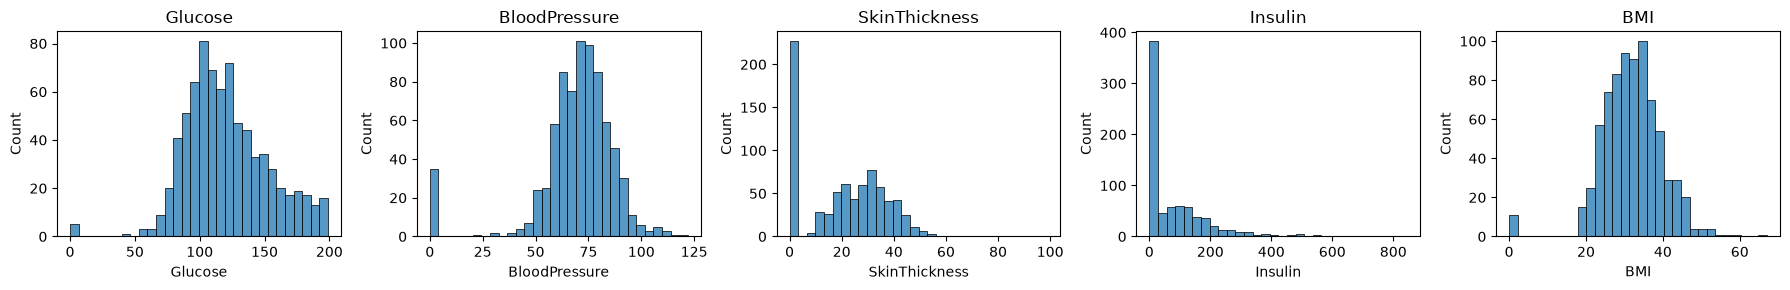

In [4]:
ZERO_AS_NAN_COLS = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]
CATEGORICAL_COLS = ["Outcome"]

print("Valori NaN espliciti:", df.isna().sum().sum())
print("\nZeri impossibili per colonna:")
print((df[ZERO_AS_NAN_COLS] == 0).sum())

# Visualizziamo il problema
fig, axes = plt.subplots(1, 5, figsize=(18, 3))
for ax, col in zip(axes, ZERO_AS_NAN_COLS):
    sns.histplot(df[col], bins=30, ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

### Preprocessing
- **Valori nulli:** zeri impossibili → NaN → sostituiti con la mediana
- **Normalizzazione:** MinMaxScaler sulle variabili numeriche
- **Codifica:** One-Hot Encoding sulla variabile categorica `Outcome`

In [5]:
class DataEngine:
    """
    Preprocessing per il VAE:
      1. gestione dei valori nulli (zeri impossibili -> NaN -> mediana)
      2. MinMaxScaler sulle variabili numeriche
      3. OneHotEncoder sulle variabili categoriche
    """

    def __init__(self, categorical_cols=None, zero_as_nan_cols=None, decimals=None):
        self.categorical_cols = categorical_cols or []
        self.zero_as_nan_cols = zero_as_nan_cols or []
        self.decimals = decimals or {}
        self.numeric_cols = []
        self.scaler = MinMaxScaler()
        self.encoder = OneHotEncoder(sparse_output=False, handle_unknown="ignore")
        self.medians = {}
        self.cat_group_sizes = []
        self.is_fitted = False

    def _handle_nulls(self, df):
        df = df.copy()
        for col in self.zero_as_nan_cols:
            df[col] = df[col].replace(0, np.nan)
        for col, median in self.medians.items():
            df[col] = df[col].fillna(median)
        return df

    def fit(self, df):
        self.numeric_cols = [c for c in df.columns if c not in self.categorical_cols]

        tmp = df.copy()
        for col in self.zero_as_nan_cols:
            tmp[col] = tmp[col].replace(0, np.nan)
        self.medians = tmp[self.numeric_cols].median().to_dict()

        clean = self._handle_nulls(df)
        self.scaler.fit(clean[self.numeric_cols])
        if self.categorical_cols:
            self.encoder.fit(clean[self.categorical_cols])
            self.cat_group_sizes = [len(c) for c in self.encoder.categories_]

        self.is_fitted = True
        return self

    def transform(self, df):
        if not self.is_fitted:
            raise RuntimeError("Chiama fit() prima di transform().")
        clean = self._handle_nulls(df)
        num = self.scaler.transform(clean[self.numeric_cols])
        if self.categorical_cols:
            cat = self.encoder.transform(clean[self.categorical_cols])
            return np.hstack([num, cat]).astype(np.float32)
        return num.astype(np.float32)

    def fit_transform(self, df):
        return self.fit(df).transform(df)

    def inverse_transform(self, X):
        n_num = len(self.numeric_cols)
        num = np.clip(X[:, :n_num], 0, 1)
        num = self.scaler.inverse_transform(num)
        out = pd.DataFrame(num, columns=self.numeric_cols)

        for col, d in self.decimals.items():
            out[col] = out[col].round(d)
            if d == 0:
                out[col] = out[col].astype(int)
                
        if self.categorical_cols:
            cat_values = self.encoder.inverse_transform(X[:, n_num:])
            for i, col in enumerate(self.categorical_cols):
                out[col] = cat_values[:, i]
        return out

    @property
    def n_features(self):
        return len(self.numeric_cols) + sum(self.cat_group_sizes)

In [6]:
DECIMALS = {
    "Pregnancies":0, "Glucose":0, "BloodPressure":0, "SkinThickness":0, "Insulin":0, "Age":0, "BMI":1, "DiabetesPedigreeFunction":3,
}

engine = DataEngine(categorical_cols=CATEGORICAL_COLS, zero_as_nan_cols=ZERO_AS_NAN_COLS, decimals=DECIMALS)
X = engine.fit_transform(df)

print("Matrice preprocessata:", X.shape)
print("Min:", X.min().round(3), "| Max:", X.max().round(3))
print("Feature totali (input del VAE):", engine.n_features)
print("Gruppi one-hot:", engine.cat_group_sizes)
print("Mediane usate per i nulli:", {k: round(v, 2) for k, v in engine.medians.items()})

Matrice preprocessata: (768, 10)
Min: 0.0 | Max: 1.0
Feature totali (input del VAE): 10
Gruppi one-hot: [2]
Mediane usate per i nulli: {'Pregnancies': 3.0, 'Glucose': 117.0, 'BloodPressure': 72.0, 'SkinThickness': 29.0, 'Insulin': 125.0, 'BMI': 32.3, 'DiabetesPedigreeFunction': 0.37, 'Age': 29.0}


In [7]:
df_back = engine.inverse_transform(X)
print("Zeri impossibili rimasti dopo il preprocessing:")
print((df_back[ZERO_AS_NAN_COLS] == 0).sum())
df_back.head()

Zeri impossibili rimasti dopo il preprocessing:
Glucose          0
BloodPressure    0
SkinThickness    0
Insulin          0
BMI              0
dtype: int64


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,125,33.599998,0.627,50,1
1,1,85,66,29,125,26.600000,0.351,31,0
2,8,183,64,29,125,23.299999,0.672,32,1
3,1,89,66,23,94,28.100000,0.167,21,0
4,0,137,40,35,168,43.099998,2.288,33,1


## Fase 2: Il Cuore Generativo – VAE
Architettura con strati densi (Fully Connected):
- **Encoder:** input → (μ, log σ²) che definiscono lo spazio latente
- **Reparameterization Trick:** z = μ + σ·ε per permettere la backpropagation
- **Decoder:** z → ricostruzione del vettore originale
- **Loss:** Reconstruction Loss (MSE) + KL Divergence

In [8]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset

SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

Device: cpu


In [9]:
INPUT_DIM  = engine.n_features            # 10
N_NUMERIC  = len(engine.numeric_cols)     # 8
CAT_GROUPS = engine.cat_group_sizes       # [2]

HIDDEN_DIM = 128
LATENT_DIM = 8
BETA       = 0.005   # peso della KL Divergence (spiegato nella cella della loss)
EPOCHS     = 500
BATCH_SIZE = 64
LR         = 1e-3

In [10]:
class Encoder(nn.Module):
    """Comprime il vettore dei dati in media e log-varianza dello spazio latente."""

    def __init__(self, input_dim, hidden_dim, latent_dim):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim // 2),
            nn.ReLU(),
        )
        self.fc_mu = nn.Linear(hidden_dim // 2, latent_dim)
        self.fc_logvar = nn.Linear(hidden_dim // 2, latent_dim)

    def forward(self, x):
        h = self.net(x)
        return self.fc_mu(h), self.fc_logvar(h)

In [11]:
def reparameterize(mu, logvar):
    """
    z = mu + sigma * epsilon,  con epsilon ~ N(0, I)
    Il campionamento casuale è spostato su epsilon, quindi il gradiente
    può fluire attraverso mu e logvar durante la backpropagation.
    """
    std = torch.exp(0.5 * logvar)      # sigma = exp(log(sigma^2) / 2)
    eps = torch.randn_like(std)        # rumore dalla normale standard
    return mu + eps * std

In [12]:
class Decoder(nn.Module):
    """Ricostruisce il vettore originale a partire da un punto dello spazio latente."""

    def __init__(self, latent_dim, hidden_dim, output_dim, n_numeric, cat_groups):
        super().__init__()
        self.n_numeric = n_numeric
        self.cat_groups = cat_groups
        self.net = nn.Sequential(
            nn.Linear(latent_dim, hidden_dim // 2),
            nn.ReLU(),
            nn.Linear(hidden_dim // 2, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, output_dim),
        )

    def forward(self, z):
        out = self.net(z)
        # Numeriche: sigmoid -> [0, 1], come l'output del MinMaxScaler
        parts = [torch.sigmoid(out[:, :self.n_numeric])]
        # Categoriche: softmax su ogni gruppo one-hot -> probabilità che sommano a 1
        start = self.n_numeric
        for size in self.cat_groups:
            parts.append(F.softmax(out[:, start:start + size], dim=1))
            start += size
        return torch.cat(parts, dim=1)

In [13]:
class VAE(nn.Module):
    def __init__(self, input_dim, n_numeric, cat_groups, hidden_dim=128, latent_dim=8):
        super().__init__()
        self.latent_dim = latent_dim
        self.encoder = Encoder(input_dim, hidden_dim, latent_dim)
        self.decoder = Decoder(latent_dim, hidden_dim, input_dim, n_numeric, cat_groups)

    def forward(self, x):
        mu, logvar = self.encoder(x)
        z = reparameterize(mu, logvar)
        x_recon = self.decoder(z)
        return x_recon, mu, logvar


model = VAE(INPUT_DIM, N_NUMERIC, CAT_GROUPS, HIDDEN_DIM, LATENT_DIM).to(device)
print(model)
print("Parametri addestrabili:", sum(p.numel() for p in model.parameters() if p.requires_grad))

VAE(
  (encoder): Encoder(
    (net): Sequential(
      (0): Linear(in_features=10, out_features=128, bias=True)
      (1): ReLU()
      (2): Linear(in_features=128, out_features=64, bias=True)
      (3): ReLU()
    )
    (fc_mu): Linear(in_features=64, out_features=8, bias=True)
    (fc_logvar): Linear(in_features=64, out_features=8, bias=True)
  )
  (decoder): Decoder(
    (net): Sequential(
      (0): Linear(in_features=8, out_features=64, bias=True)
      (1): ReLU()
      (2): Linear(in_features=64, out_features=128, bias=True)
      (3): ReLU()
      (4): Linear(in_features=128, out_features=10, bias=True)
    )
  )
)
Parametri addestrabili: 20890


In [14]:
def vae_loss(x_recon, x, mu, logvar, beta=BETA):
    """
    Loss = Reconstruction Loss (MSE) + beta * KL Divergence
    Entrambe sommate sulle feature e mediate sul batch.
    """
    batch_size = x.size(0)
    recon_loss = F.mse_loss(x_recon, x, reduction="sum") / batch_size
    # KL tra N(mu, sigma^2) e N(0, I), in forma chiusa
    kl_div = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp()) / batch_size
    return recon_loss + beta * kl_div, recon_loss, kl_div

In [15]:
X_tensor = torch.tensor(X, dtype=torch.float32)
loader = DataLoader(TensorDataset(X_tensor), batch_size=BATCH_SIZE, shuffle=True)
print("Batch per epoca:", len(loader))

Batch per epoca: 12


In [16]:
def train_vae(model, loader, epochs=EPOCHS, lr=LR, beta=BETA, verbose_every=50):
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    history = {"total": [], "recon": [], "kl": []}
    n_samples = len(loader.dataset)

    for epoch in range(1, epochs + 1):
        model.train()
        tot = rec = kl = 0.0
        for (batch,) in loader:
            batch = batch.to(device)
            x_recon, mu, logvar = model(batch)
            loss, r, k = vae_loss(x_recon, batch, mu, logvar, beta)

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            tot += loss.item() * batch.size(0)
            rec += r.item() * batch.size(0)
            kl  += k.item() * batch.size(0)

        history["total"].append(tot / n_samples)
        history["recon"].append(rec / n_samples)
        history["kl"].append(kl / n_samples)

        if epoch % verbose_every == 0 or epoch == 1:
            print(f"Epoca {epoch:4d} | Loss {history['total'][-1]:.4f} | "
                  f"MSE {history['recon'][-1]:.4f} | KL {history['kl'][-1]:.4f}")
    return history


history = train_vae(model, loader)

Epoca    1 | Loss 1.0613 | MSE 1.0609 | KL 0.0757
Epoca   50 | Loss 0.1336 | MSE 0.1112 | KL 4.4858
Epoca  100 | Loss 0.0925 | MSE 0.0650 | KL 5.4994
Epoca  150 | Loss 0.0739 | MSE 0.0437 | KL 6.0507
Epoca  200 | Loss 0.0701 | MSE 0.0367 | KL 6.6930
Epoca  250 | Loss 0.0663 | MSE 0.0332 | KL 6.6303
Epoca  300 | Loss 0.0657 | MSE 0.0304 | KL 7.0678
Epoca  350 | Loss 0.0647 | MSE 0.0298 | KL 6.9619
Epoca  400 | Loss 0.0615 | MSE 0.0281 | KL 6.6943
Epoca  450 | Loss 0.0607 | MSE 0.0268 | KL 6.7946
Epoca  500 | Loss 0.0608 | MSE 0.0267 | KL 6.8232


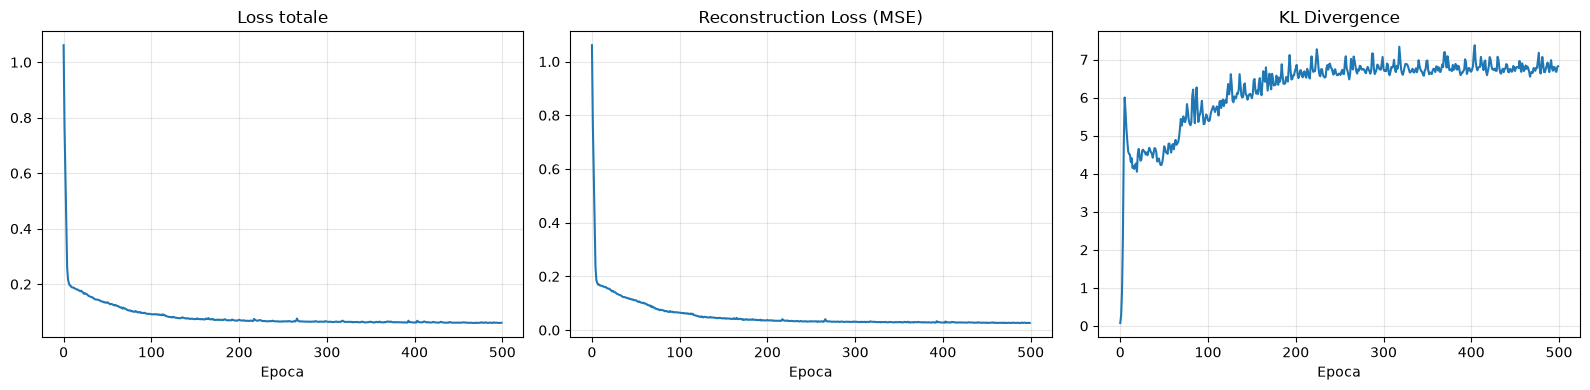

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, key, title in zip(axes, ["total", "recon", "kl"],
                          ["Loss totale", "Reconstruction Loss (MSE)", "KL Divergence"]):
    ax.plot(history[key])
    ax.set_title(title)
    ax.set_xlabel("Epoca")
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Fase 3: Generazione e Validazione
- **Sampling:** si "spegne" l'encoder, si campionano vettori z ~ N(0, I) e si passano al decoder
- **Metriche di qualità:** heatmap delle correlazioni e istogrammi delle distribuzioni
- **Privacy check:** nessun record sintetico deve essere identico a un record reale

In [18]:
from sklearn.neighbors import NearestNeighbors

In [19]:
def estimate_noise_std(model, X, n_numeric):
    """
    Deviazione standard dell'errore di ricostruzione per ogni variabile numerica.
    Rappresenta la varianza di p(x|z) che il decoder, restituendo solo la media, non modella.
    """
    model.eval()
    with torch.no_grad():
        X_t = torch.tensor(X, dtype=torch.float32, device=device)
        mu, _ = model.encoder(X_t)              # usiamo la media latente, senza campionare
        X_recon = model.decoder(mu).cpu().numpy()
    return (X[:, :n_numeric] - X_recon[:, :n_numeric]).std(axis=0)


noise_std = estimate_noise_std(model, X, N_NUMERIC)
print("Rumore stimato per variabile (scala [0,1]):")
print({col: round(float(s), 3) for col, s in zip(engine.numeric_cols, noise_std)})

Rumore stimato per variabile (scala [0,1]):
{'Pregnancies': 0.027, 'Glucose': 0.037, 'BloodPressure': 0.054, 'SkinThickness': 0.061, 'Insulin': 0.048, 'BMI': 0.043, 'DiabetesPedigreeFunction': 0.027, 'Age': 0.04}


In [20]:
def generate_synthetic(model, engine, n_samples, noise_std=None, seed=None):
    """
    Genera un dataset sintetico usando SOLO il decoder:
    l'encoder viene "spento", z viene campionato da N(0, I).
    Se noise_std è fornito, si campiona da p(x|z) = N(decoder(z), noise_std^2).
    """
    if seed is not None:
        torch.manual_seed(seed)
    model.eval()
    with torch.no_grad():
        z = torch.randn(n_samples, model.latent_dim, device=device)
        x_synth = model.decoder(z).cpu().numpy()

    if noise_std is not None:
        n_num = len(noise_std)
        rng = np.random.default_rng(seed)
        x_synth[:, :n_num] += rng.normal(0, 1, (n_samples, n_num)) * noise_std

    return engine.inverse_transform(x_synth)   # il clip in [0,1] gestisce eventuali sforamenti


df_synth = generate_synthetic(model, engine, n_samples=len(df), noise_std=noise_std, seed=SEED)
print("Shape sintetico:", df_synth.shape)
df_synth.head()

Shape sintetico: (768, 9)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,0,124,76,28,163,29.700001,0.642,21,0
1,2,146,83,38,128,34.500000,0.470,65,0
2,6,117,93,43,110,42.400002,1.431,39,0
3,1,118,74,29,166,33.400002,1.024,24,0
4,5,106,103,37,92,34.599998,0.105,50,0


In [21]:
# Dati reali "puliti" (stesso preprocessing: nulli gestiti e valori arrotondati)
df_real = engine.inverse_transform(X)

comparison = pd.concat(
    {"Reale": df_real.describe().T[["mean", "std", "min", "max"]],
     "Sintetico": df_synth.describe().T[["mean", "std", "min", "max"]]},
    axis=1,
).round(2)
display(comparison)

print("Distribuzione Outcome (%):")
pd.DataFrame({
    "Reale": df_real["Outcome"].value_counts(normalize=True),
    "Sintetico": df_synth["Outcome"].value_counts(normalize=True),
}).mul(100).round(1)

Reale                       Sintetico         \
                            mean    std    min     max      mean    std   
Pregnancies                 3.85   3.37   0.00   17.00      3.82   2.86   
Glucose                   121.66  30.44  44.00  199.00    120.04  29.70   
BloodPressure              72.39  12.10  24.00  122.00     76.06  13.37   
SkinThickness              29.11   8.79   7.00   99.00     29.22   8.88   
Insulin                   140.67  86.38  14.00  846.00    130.17  64.13   
BMI                        32.46   6.88  18.20   67.10     33.31   6.90   
DiabetesPedigreeFunction    0.47   0.33   0.08    2.42      0.48   0.29   
Age                        33.24  11.76  21.00   81.00     34.67  11.23   
Outcome                     0.35   0.48   0.00    1.00      0.33   0.47   

                                         
                            min     max  
Pregnancies                0.00   15.00  
Glucose                   44.00  199.00  
BloodPressure             31.00  115.00  
SkinThickness              7.00   57.00  
Insulin                   14.00  528.00  
BMI                       18.20   53.70  
DiabetesPedigreeFunction   0.08    1.66  
Age                       21.00   74.00  
Outcome                    0.00    1.00

Distribuzione Outcome (%):


,Reale,Sintetico
Outcome,,
0,65.1,66.8
1,34.9,33.2


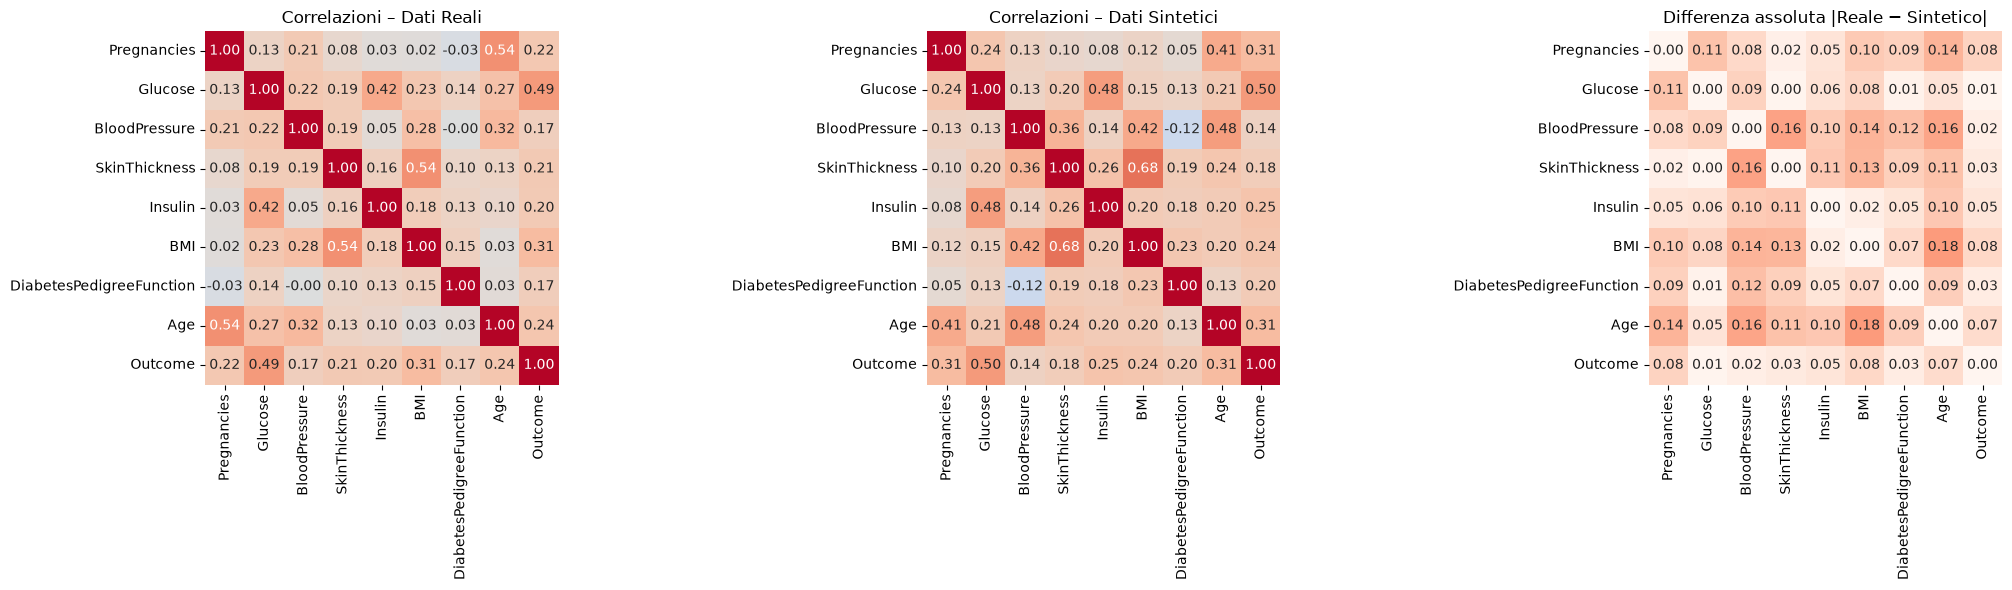

Differenza media tra le correlazioni: 0.080


In [22]:
corr_real = df_real.corr()
corr_synth = df_synth.corr()
corr_diff = (corr_real - corr_synth).abs()

fig, axes = plt.subplots(1, 3, figsize=(22, 6))
kw = dict(annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, square=True, cbar=False)

sns.heatmap(corr_real, ax=axes[0], **kw)
axes[0].set_title("Correlazioni – Dati Reali")

sns.heatmap(corr_synth, ax=axes[1], **kw)
axes[1].set_title("Correlazioni – Dati Sintetici")

sns.heatmap(corr_diff, ax=axes[2], annot=True, fmt=".2f", cmap="Reds",
            vmin=0, vmax=0.5, square=True, cbar=False)
axes[2].set_title("Differenza assoluta |Reale − Sintetico|")

plt.tight_layout()
plt.show()

# Media della differenza solo sopra la diagonale (ogni coppia contata una volta)
upper = np.triu_indices_from(corr_diff, k=1)
print(f"Differenza media tra le correlazioni: {corr_diff.values[upper].mean():.3f}")

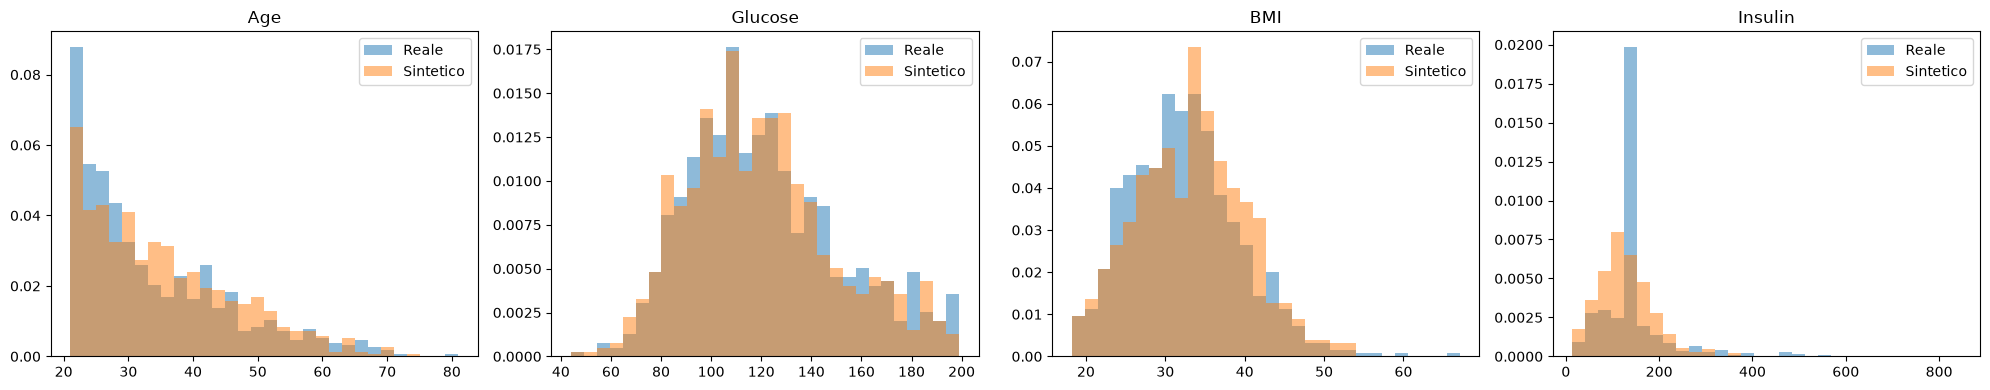

In [23]:
KEY_VARS = ["Age", "Glucose", "BMI", "Insulin"]

fig, axes = plt.subplots(1, len(KEY_VARS), figsize=(20, 4))
for ax, col in zip(axes, KEY_VARS):
    bins = np.histogram_bin_edges(df_real[col], bins=30)   # stessi bin per entrambi
    ax.hist(df_real[col], bins=bins, alpha=0.5, density=True, label="Reale")
    ax.hist(df_synth[col], bins=bins, alpha=0.5, density=True, label="Sintetico")
    ax.set_title(col)
    ax.legend()
plt.tight_layout()
plt.show()

Record sintetici identici a record reali: 0 su 768
DCR mediana sintetico→reale: 0.1721
DCR mediana reale→reale    : 0.1626
DCR minima sintetico→reale : 0.0292


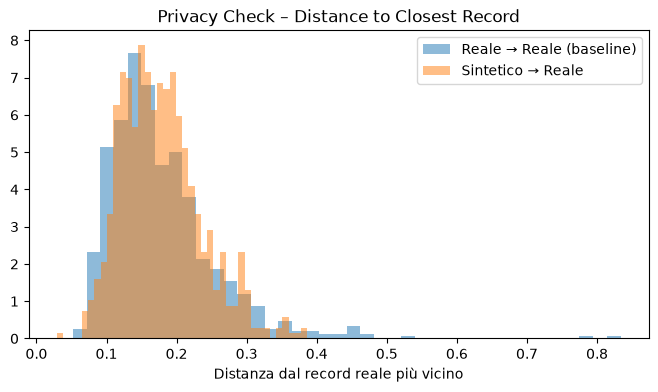

In [24]:
# 1) Record sintetici IDENTICI a record reali
real_set = set(map(tuple, df_real.values.tolist()))
exact_copies = sum(tuple(row) in real_set for row in df_synth.values.tolist())
print(f"Record sintetici identici a record reali: {exact_copies} su {len(df_synth)}")

# 2) Distance to Closest Record (DCR) nello spazio normalizzato
X_real_scaled = engine.transform(df_real)
X_synth_scaled = engine.transform(df_synth)

nn_real = NearestNeighbors(n_neighbors=2).fit(X_real_scaled)
dcr_synth = nn_real.kneighbors(X_synth_scaled, n_neighbors=1)[0][:, 0]   # sintetico -> reale più vicino
dcr_real = nn_real.kneighbors(X_real_scaled, n_neighbors=2)[0][:, 1]     # reale -> altro reale più vicino (escluso sé stesso)

print(f"DCR mediana sintetico→reale: {np.median(dcr_synth):.4f}")
print(f"DCR mediana reale→reale    : {np.median(dcr_real):.4f}")
print(f"DCR minima sintetico→reale : {dcr_synth.min():.4f}")

plt.figure(figsize=(8, 4))
plt.hist(dcr_real, bins=40, alpha=0.5, density=True, label="Reale → Reale (baseline)")
plt.hist(dcr_synth, bins=40, alpha=0.5, density=True, label="Sintetico → Reale")
plt.xlabel("Distanza dal record reale più vicino")
plt.title("Privacy Check – Distance to Closest Record")
plt.legend()
plt.show()

In [25]:
df_synth.to_csv("synthetic_pima.csv", index=False)
print("Salvato: synthetic_pima.csv")

Salvato: synthetic_pima.csv


In [26]:
import os
from dotenv import load_dotenv
from openai import OpenAI

load_dotenv(override=True)   # override=True rilegge il .env anche se è già stato caricato
print("Chiave trovata:", os.getenv("GROQ_API_KEY") is not None)

client = OpenAI(
    base_url="https://api.groq.com/openai/v1",
    api_key=os.getenv("GROQ_API_KEY"),
)

response = client.chat.completions.create(
    model="openai/gpt-oss-120b",
    messages=[{"role": "user", "content": "Rispondi solo con: OK"}],
)
print(response.choices[0].message.content)

Chiave trovata: True
OK


## Fase 4: Integrazione LLM "Natural Language Analyst"
- **Setup:** collegamento tramite SDK OpenAI (provider Groq, modello `openai/gpt-oss-120b`)
- **Prompt Engineering:** system prompt costruito dinamicamente con la struttura del dataset sintetico
- **Functionality:** domanda in linguaggio naturale → l'LLM genera codice Pandas + Matplotlib →
  il backend lo valida e lo esegue in modo sicuro → restituisce risultato e grafico

In [27]:
import os, re, ast, sys, json, base64, subprocess
from dotenv import load_dotenv
from openai import OpenAI
from IPython.display import Image, Markdown, display

load_dotenv(override=True)

client = OpenAI(
    base_url="https://api.groq.com/openai/v1",
    api_key=os.getenv("GROQ_API_KEY"),
)
LLM_MODEL = "openai/gpt-oss-120b"
SYNTH_CSV = os.path.abspath("synthetic_pima.csv")   # salvato nella cella 29

print("Chiave trovata:", os.getenv("GROQ_API_KEY") is not None)
print("Dataset sintetico:", SYNTH_CSV, "| esiste:", os.path.exists(SYNTH_CSV))

Chiave trovata: True
Dataset sintetico: c:\Users\logic\Desktop\PROGRAMMAZIONE\GitHub\Progetto_M6_Synthetic_Data_Sandbox\synthetic_pima.csv | esiste: True


In [28]:
%%writefile sandbox_runner.py
# Eseguito in un processo separato: riceve il codice via stdin e restituisce un JSON
import sys, io, json, base64, builtins, contextlib
import matplotlib
matplotlib.use("Agg")                     # backend senza finestre: disegna in memoria
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

payload = json.loads(sys.stdin.buffer.read().decode("utf-8"))
df = pd.read_csv(payload["csv_path"])
safe_builtins = {n: getattr(builtins, n) for n in payload["builtins"]}
namespace = {"__builtins__": safe_builtins, "df": df, "pd": pd, "np": np, "plt": plt}

result = {"ok": True, "output": "", "image": None, "error": None}
buffer = io.StringIO()
try:
    with contextlib.redirect_stdout(buffer):              # cattura i print()
        exec(compile(payload["code"], "<codice_llm>", "exec"), namespace)
    if plt.get_fignums():                                  # se è stato creato un grafico
        img = io.BytesIO()
        plt.gcf().savefig(img, format="png", dpi=110, bbox_inches="tight")
        result["image"] = base64.b64encode(img.getvalue()).decode("ascii")
except Exception as e:
    result["ok"] = False
    result["error"] = f"{type(e).__name__}: {e}"
result["output"] = buffer.getvalue()[:5000]
sys.stdout.buffer.write(json.dumps(result).encode("utf-8"))

Overwriting sandbox_runner.py


In [29]:
ALLOWED_MODULES = {"pandas", "numpy", "matplotlib"}

FORBIDDEN_NAMES = {
    "open", "exec", "eval", "compile", "__import__", "globals", "locals", "vars",
    "getattr", "setattr", "delattr", "input", "breakpoint", "exit", "quit", "help",
    "memoryview", "os", "sys", "subprocess", "shutil", "pathlib", "builtins",
}

FORBIDDEN_ATTRS = {
    "savefig", "imread", "eval", "query", "load", "save", "savez", "savetxt",
    "loadtxt", "genfromtxt", "fromfile", "tofile", "memmap", "system", "popen",
}
ALLOWED_TO_METHODS = {"to_frame", "to_numpy", "to_string", "to_dict", "to_list", "to_markdown"}

SAFE_BUILTINS = [
    "abs", "all", "any", "bool", "dict", "enumerate", "filter", "float", "format",
    "int", "isinstance", "len", "list", "map", "max", "min", "print", "range",
    "reversed", "round", "set", "sorted", "str", "sum", "tuple", "zip",
    "ValueError", "KeyError", "TypeError", "Exception",
]


def validate_code(code):
    """
    Analizza il codice con l'AST (senza eseguirlo) e lo rifiuta se contiene
    operazioni pericolose. Rimuove gli import consentiti, perché pd/np/plt
    vengono già forniti. Restituisce (codice_pulito, None) o (None, errore).
    """
    try:
        tree = ast.parse(code)
    except SyntaxError as e:
        return None, f"Errore di sintassi: {e}"

    # 1) Import: consentiti solo pandas/numpy/matplotlib, e vengono rimossi
    new_body = []
    for node in tree.body:
        if isinstance(node, (ast.Import, ast.ImportFrom)):
            modules = [a.name for a in node.names] if isinstance(node, ast.Import) else [node.module or ""]
            for m in modules:
                if m.split(".")[0] not in ALLOWED_MODULES:
                    return None, f"Import non consentito: '{m}'. Usa solo df, pd, np e plt."
            continue
        new_body.append(node)
    tree.body = new_body

    # 2) Controllo di ogni nodo dell'albero
    for node in ast.walk(tree):
        if isinstance(node, (ast.Import, ast.ImportFrom)):
            return None, "Gli import sono consentiti solo all'inizio del codice."
        if isinstance(node, (ast.ClassDef, ast.Global, ast.Nonlocal, ast.AsyncFunctionDef)):
            return None, f"Costrutto non consentito: {type(node).__name__}."
        if isinstance(node, ast.Name) and node.id in FORBIDDEN_NAMES:
            return None, f"Nome non consentito: '{node.id}'."
        if isinstance(node, ast.Attribute):
            a = node.attr
            if a.startswith("_"):
                return None, f"Accesso ad attributi privati non consentito: '{a}'."
            if a in FORBIDDEN_ATTRS or a.startswith("read_") or (a.startswith("to_") and a not in ALLOWED_TO_METHODS):
                return None, f"Metodo non consentito (accesso a file o esecuzione dinamica): '{a}'."

    return ast.unparse(tree), None

In [30]:
RUNNER_PATH = os.path.abspath("sandbox_runner.py")


def run_code_safely(code, csv_path, timeout=20):
    """
    Valida il codice e lo esegue in un processo separato con timeout.
    Restituisce un dizionario: ok, output (testo stampato), image (PNG base64), error.
    """
    safe_code, error = validate_code(code)
    if error:
        return {"ok": False, "output": "", "image": None, "error": f"Codice rifiutato: {error}"}

    payload = json.dumps({"code": safe_code, "csv_path": csv_path, "builtins": SAFE_BUILTINS})
    try:
        proc = subprocess.run(
            [sys.executable, RUNNER_PATH],     # stesso Python dell'ambiente virtuale
            input=payload.encode("utf-8"),
            capture_output=True,
            timeout=timeout,
        )
    except subprocess.TimeoutExpired:
        return {"ok": False, "output": "", "image": None,
                "error": f"Timeout: esecuzione oltre {timeout} secondi."}

    try:
        return json.loads(proc.stdout.decode("utf-8"))
    except json.JSONDecodeError:
        return {"ok": False, "output": "", "image": None,
                "error": "Errore del processo di esecuzione: " + proc.stderr.decode("utf-8", "replace")[-500:]}

In [31]:
security_tests = {
    "Codice lecito":         "print(df['Glucose'].mean())",
    "Import di os":          "import os\nos.system('dir')",
    "Apertura file":         "f = open('segreti.txt', 'w')",
    "Fuga dalla sandbox":    "().__class__.__bases__[0].__subclasses__()",
    "Esportazione dati":     "df.to_csv('copia.csv')",
    "Lettura altri file":    "pd.read_csv('dati_reali.csv')",
    "Ciclo infinito":        "while True:\n    pass",
}

for name, code in security_tests.items():
    r = run_code_safely(code, SYNTH_CSV, timeout=5)
    status = "✅ eseguito" if r["ok"] else "⛔ bloccato"
    print(f"{name:20s} {status:12s} {r['error'] or r['output'].strip()}")

Codice lecito        ✅ eseguito   120.03776041666667
Import di os         ⛔ bloccato   Codice rifiutato: Import non consentito: 'os'. Usa solo df, pd, np e plt.
Apertura file        ⛔ bloccato   Codice rifiutato: Nome non consentito: 'open'.
Fuga dalla sandbox   ⛔ bloccato   Codice rifiutato: Accesso ad attributi privati non consentito: '__subclasses__'.
Esportazione dati    ⛔ bloccato   Codice rifiutato: Metodo non consentito (accesso a file o esecuzione dinamica): 'to_csv'.
Lettura altri file   ⛔ bloccato   Codice rifiutato: Metodo non consentito (accesso a file o esecuzione dinamica): 'read_csv'.
Ciclo infinito       ⛔ bloccato   Timeout: esecuzione oltre 5 secondi.


In [32]:
COLUMN_DESCRIPTIONS = {
    "Pregnancies": "numero di gravidanze",
    "Glucose": "glicemia (mg/dL) dopo test di tolleranza al glucosio",
    "BloodPressure": "pressione diastolica (mm Hg)",
    "SkinThickness": "spessore della plica cutanea del tricipite (mm)",
    "Insulin": "insulina sierica a 2 ore (mu U/ml)",
    "BMI": "indice di massa corporea (kg/m^2)",
    "DiabetesPedigreeFunction": "indice di predisposizione genetica al diabete",
    "Age": "età (anni)",
    "Outcome": "diagnosi di diabete (0 = no, 1 = sì)",
}


def build_system_prompt(df, descriptions=None):
    """Costruisce il system prompt a partire dalla struttura REALE del DataFrame."""
    descriptions = descriptions or {}
    lines = []
    for col in df.columns:
        s = df[col]
        desc = descriptions.get(col, "")
        if pd.api.types.is_numeric_dtype(s) and s.nunique() > 10:
            stats = f"min={s.min():.4g}, max={s.max():.4g}, media={s.mean():.4g}"
        else:
            stats = "valori: " + ", ".join(map(str, sorted(s.unique())[:10]))
        lines.append(f"- {col} ({s.dtype}){': ' + desc if desc else ''} | {stats}")
    schema = "\n".join(lines)

    return f"""Sei un "Natural Language Analyst": un data analyst esperto in Python, Pandas e Matplotlib.
Rispondi alle domande dell'utente su un dataset SINTETICO (generato da un VAE) caricato nel DataFrame `df`.

STRUTTURA DEL DATASET ({len(df)} righe, {df.shape[1]} colonne):
{schema}

REGOLE PER IL CODICE:
1. Le variabili `df`, `pd` (pandas), `np` (numpy) e `plt` (matplotlib.pyplot) sono GIÀ disponibili: non serve importare nulla.
2. Usa SOLO le colonne elencate sopra, con i nomi esatti.
3. Stampa sempre il risultato numerico con print(), in modo leggibile.
4. Se un grafico aiuta a rispondere, crea UNA sola figura con plt (titolo e assi in italiano). Non chiamare plt.savefig().
5. Vietato: leggere o scrivere file, usare import diversi da pandas/numpy/matplotlib, usare eval, query, open, os, sys.
6. Il codice deve essere in UN SOLO blocco ```python ... ```.

FORMATO DELLA RISPOSTA:
- Una o due frasi in italiano che spiegano l'approccio.
- Il blocco di codice.

Se la domanda riguarda informazioni NON presenti nel dataset (ad esempio colonne che non esistono),
NON scrivere codice: spiega in italiano che quei dati non sono disponibili ed elenca le colonne utilizzabili."""


print(build_system_prompt(df_synth, COLUMN_DESCRIPTIONS))

Sei un "Natural Language Analyst": un data analyst esperto in Python, Pandas e Matplotlib.
Rispondi alle domande dell'utente su un dataset SINTETICO (generato da un VAE) caricato nel DataFrame `df`.

STRUTTURA DEL DATASET (768 righe, 9 colonne):
- Pregnancies (int64): numero di gravidanze | min=0, max=15, media=3.815
- Glucose (int64): glicemia (mg/dL) dopo test di tolleranza al glucosio | min=44, max=199, media=120
- BloodPressure (int64): pressione diastolica (mm Hg) | min=31, max=115, media=76.06
- SkinThickness (int64): spessore della plica cutanea del tricipite (mm) | min=7, max=57, media=29.22
- Insulin (int64): insulina sierica a 2 ore (mu U/ml) | min=14, max=528, media=130.2
- BMI (float32): indice di massa corporea (kg/m^2) | min=18.2, max=53.7, media=33.31
- DiabetesPedigreeFunction (float32): indice di predisposizione genetica al diabete | min=0.078, max=1.657, media=0.479
- Age (int64): età (anni) | min=21, max=74, media=34.67
- Outcome (int64): diagnosi di diabete (0 = no,

In [33]:
def ask_llm(messages, temperature=0.1):
    """Unico punto di contatto con il provider LLM: per cambiarlo basta modificare questa funzione."""
    response = client.chat.completions.create(
        model=LLM_MODEL, messages=messages, temperature=temperature,
    )
    return response.choices[0].message.content or ""


def extract_code(text):
    """Estrae il primo blocco di codice ```python ... ``` dalla risposta dell'LLM."""
    match = re.search(r"```(?:python|py)?\s*\n(.*?)```", text, re.DOTALL)
    return match.group(1).strip() if match else None

In [34]:
def analyze(question, df, csv_path, max_attempts=3, verbose=True):
    """
    Domanda -> LLM genera codice -> validazione + esecuzione sicura -> risultato.
    Se il codice fallisce, l'errore viene rimandato all'LLM per correggerlo.
    """
    messages = [
        {"role": "system", "content": build_system_prompt(df, COLUMN_DESCRIPTIONS)},
        {"role": "user", "content": question},
    ]
    result = {"question": question, "explanation": "", "code": None, "output": "",
              "image": None, "error": None, "attempts": 0}

    for attempt in range(1, max_attempts + 1):
        result["attempts"] = attempt
        reply = ask_llm(messages)
        code = extract_code(reply)
        result["explanation"] = re.sub(r"```.*?```", "", reply, flags=re.DOTALL).strip()

        if code is None:                     # nessun codice: risposta solo testuale
            result["error"] = None
            return result

        result["code"] = code
        execution = run_code_safely(code, csv_path)
        result.update(output=execution["output"], image=execution["image"], error=execution["error"])

        if execution["ok"]:
            return result

        if verbose:
            print(f"Tentativo {attempt} fallito -> {execution['error']}")
        messages += [
            {"role": "assistant", "content": reply},
            {"role": "user", "content": f"Il codice ha prodotto questo errore:\n{execution['error']}\n"
                                        "Correggilo rispettando le regole e restituisci il codice completo."},
        ]
    return result

In [35]:
def show_result(res, show_code=True):
    display(Markdown(f"**Domanda:** {res['question']}"))
    if res["explanation"]:
        display(Markdown(res["explanation"]))
    if show_code and res["code"]:
        display(Markdown(f"```python\n{res['code']}\n```"))
    if res["output"]:
        print(res["output"])
    if res["image"]:
        display(Image(data=base64.b64decode(res["image"])))
    if res["error"]:
        print("⚠️", res["error"])
    print(f"(tentativi: {res['attempts']})")

In [36]:
res = analyze("Qual è la correlazione tra reddito e risparmio?", df_synth, SYNTH_CSV)
show_result(res)

**Domanda:** Qual è la correlazione tra reddito e risparmio?

Nel dataset non sono presenti le colonne **reddito** né **risparmio**, quindi non è possibile calcolare la correlazione tra queste variabili.  
Le colonne disponibili sono: **Pregnancies, Glucose, BloodPressure, SkinThickness, Insulin, BMI, DiabetesPedigreeFunction, Age, Outcome**.

(tentativi: 1)


**Domanda:** Qual è la correlazione tra glicemia e BMI?

Per calcolare la correlazione di Pearson tra la glicemia (**Glucose**) e il BMI (**BMI**) usiamo il metodo `corr` di pandas e, per visualizzare meglio la relazione, mostriamo anche un grafico a dispersione.

```python
# Calcolo della correlazione Pearson
corr = df['Glucose'].corr(df['BMI'])
print(f"Correlazione Pearson tra Glucose e BMI: {corr:.4f}")

# Grafico a dispersione per visualizzare la relazione
plt.figure(figsize=(6,4))
plt.scatter(df['Glucose'], df['BMI'], alpha=0.7, edgecolor='k')
plt.title('Correlazione tra Glucose e BMI')
plt.xlabel('Glucose (mg/dL)')
plt.ylabel('BMI (kg/m²)')
plt.grid(True)
plt.show()
```

Correlazione Pearson tra Glucose e BMI: 0.1510



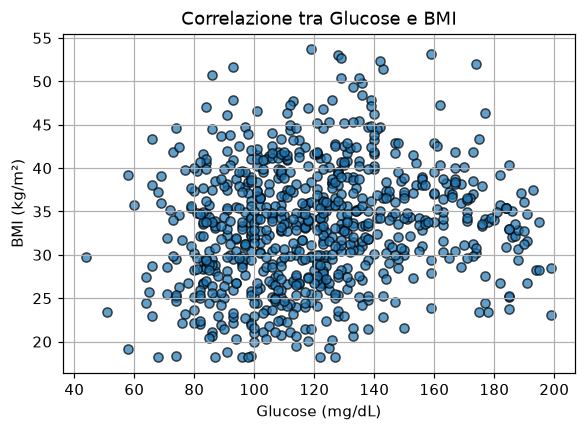

(tentativi: 1)


In [37]:
res = analyze("Qual è la correlazione tra glicemia e BMI?", df_synth, SYNTH_CSV)
show_result(res)

**Domanda:** Confronta l'età media tra pazienti diabetici e non diabetici con un grafico a barre

Per confrontare l’età media dei pazienti con diagnosi di diabete (Outcome = 1) e senza diabete (Outcome = 0) calcoliamo la media della colonna **Age** per ciascun gruppo e visualizziamo i due valori con un grafico a barre.

```python
# Calcolo dell'età media per ciascun valore di Outcome
media_eta = df.groupby('Outcome')['Age'].mean().reset_index()
media_eta.columns = ['Outcome', 'Età media']

# Stampa dei risultati
print("Età media per gruppo:")
print(media_eta)

# Grafico a barre
plt.figure(figsize=(6,4))
plt.bar(media_eta['Outcome'].astype(str), media_eta['Età media'], color=['steelblue','tomato'])
plt.title('Età media per diagnosi di diabete')
plt.xlabel('Outcome (0 = No diabete, 1 = Diabete)')
plt.ylabel('Età media (anni)')
plt.ylim(0, media_eta['Età media'].max() + 5)
plt.show()
```

Età media per gruppo:
   Outcome  Età media
0        0  32.235867
1        1  39.560784



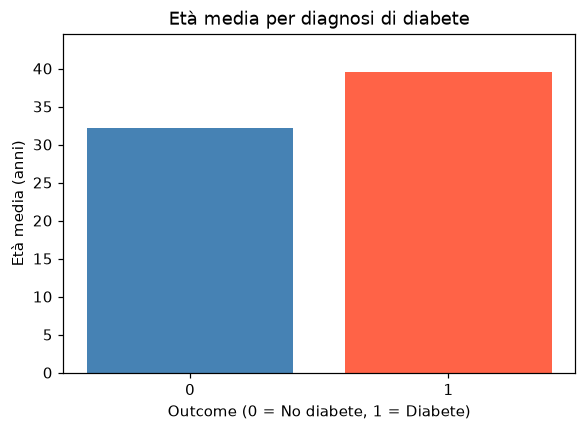

(tentativi: 1)


In [38]:
res = analyze("Confronta l'età media tra pazienti diabetici e non diabetici con un grafico a barre", df_synth, SYNTH_CSV)
show_result(res)

## Fase 5: API e UI
I componenti vengono salvati come moduli Python con `%%writefile`,
così il backend FastAPI e la UI Streamlit (processi separati) possono importarli.

In [39]:
df.to_csv("pima_real.csv", index=False)
print("Salvato pima_real.csv:", df.shape)

Salvato pima_real.csv: (768, 9)


In [40]:
%%writefile data_engine.py
"""Data Engine: preprocessing dei dati (gestione nulli, scaling e codifica)."""
import numpy as np
import pandas as pd
from sklearn.preprocessing import MinMaxScaler, OneHotEncoder

PIMA_ZERO_AS_NAN = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]


class DataEngine:
    """
    Preprocessing per il VAE:
      1. gestione dei valori nulli (zeri impossibili -> NaN -> mediana / moda)
      2. MinMaxScaler sulle variabili numeriche
      3. OneHotEncoder sulle variabili categoriche
    """

    def __init__(self, categorical_cols=None, zero_as_nan_cols=None, decimals=None):
        self.categorical_cols = categorical_cols or []
        self.zero_as_nan_cols = zero_as_nan_cols or []
        self.decimals = decimals or {}
        self.numeric_cols = []
        self.scaler = MinMaxScaler()
        self.encoder = OneHotEncoder(sparse_output=False, handle_unknown="ignore")
        self.medians = {}
        self.modes = {}
        self.cat_group_sizes = []
        self.is_fitted = False

    def _handle_nulls(self, df):
        df = df.copy()
        for col in self.zero_as_nan_cols:
            df[col] = df[col].replace(0, np.nan)
        for col, median in self.medians.items():
            df[col] = df[col].fillna(median)
        for col, mode in self.modes.items():
            df[col] = df[col].fillna(mode)
        return df

    def fit(self, df):
        self.numeric_cols = [c for c in df.columns if c not in self.categorical_cols]

        tmp = df.copy()
        for col in self.zero_as_nan_cols:
            tmp[col] = tmp[col].replace(0, np.nan)
        self.medians = tmp[self.numeric_cols].median().to_dict()
        self.modes = {c: tmp[c].mode().iloc[0] for c in self.categorical_cols}

        clean = self._handle_nulls(df)
        self.scaler.fit(clean[self.numeric_cols])
        if self.categorical_cols:
            self.encoder.fit(clean[self.categorical_cols])
            self.cat_group_sizes = [len(c) for c in self.encoder.categories_]

        self.is_fitted = True
        return self

    def transform(self, df):
        if not self.is_fitted:
            raise RuntimeError("Chiama fit() prima di transform().")
        clean = self._handle_nulls(df)
        num = self.scaler.transform(clean[self.numeric_cols])
        if self.categorical_cols:
            cat = self.encoder.transform(clean[self.categorical_cols])
            return np.hstack([num, cat]).astype(np.float32)
        return num.astype(np.float32)

    def fit_transform(self, df):
        return self.fit(df).transform(df)

    def inverse_transform(self, X):
        n_num = len(self.numeric_cols)
        num = np.clip(X[:, :n_num], 0, 1)
        num = self.scaler.inverse_transform(num)
        out = pd.DataFrame(num, columns=self.numeric_cols)

        for col, d in self.decimals.items():
            if col in out.columns:
                out[col] = out[col].round(d)
                if d == 0:
                    out[col] = out[col].astype(int)

        if self.categorical_cols:
            cat_values = self.encoder.inverse_transform(X[:, n_num:])
            for i, col in enumerate(self.categorical_cols):
                out[col] = cat_values[:, i]
        return out

    @property
    def n_features(self):
        return len(self.numeric_cols) + sum(self.cat_group_sizes)


def infer_decimals(df, numeric_cols, max_decimals=4):
    """Per ogni colonna numerica trova il numero minimo di decimali che la rappresenta."""
    decimals = {}
    for col in numeric_cols:
        s = df[col].dropna().astype(float)
        for d in range(max_decimals + 1):
            if np.allclose(s, s.round(d)):
                decimals[col] = d
                break
        else:
            decimals[col] = max_decimals
    return decimals


def suggest_config(df):
    """
    Suggerimenti automatici per un dataset caricato dall'utente:
    - categoriche: colonne testuali/booleane o intere binarie (es. 0/1)
    - zero = nullo: solo se il dataset è il Pima Indians Diabetes
    """
    categorical = []
    for col in df.columns:
        s = df[col]
        if not pd.api.types.is_numeric_dtype(s) or pd.api.types.is_bool_dtype(s):
            categorical.append(col)
        elif pd.api.types.is_integer_dtype(s) and s.nunique() <= 2:
            categorical.append(col)
    zero_as_nan = PIMA_ZERO_AS_NAN if set(PIMA_ZERO_AS_NAN).issubset(df.columns) else []
    return categorical, zero_as_nan

Overwriting data_engine.py


In [41]:
%%writefile vae.py
"""Generative Core: Variational Autoencoder in PyTorch."""
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")


class Encoder(nn.Module):
    """Comprime il vettore dei dati in media e log-varianza dello spazio latente."""

    def __init__(self, input_dim, hidden_dim, latent_dim):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim // 2),
            nn.ReLU(),
        )
        self.fc_mu = nn.Linear(hidden_dim // 2, latent_dim)
        self.fc_logvar = nn.Linear(hidden_dim // 2, latent_dim)

    def forward(self, x):
        h = self.net(x)
        return self.fc_mu(h), self.fc_logvar(h)


def reparameterize(mu, logvar):
    """z = mu + sigma * epsilon, con epsilon ~ N(0, I)."""
    std = torch.exp(0.5 * logvar)
    eps = torch.randn_like(std)
    return mu + eps * std


class Decoder(nn.Module):
    """Ricostruisce il vettore originale a partire da un punto dello spazio latente."""

    def __init__(self, latent_dim, hidden_dim, output_dim, n_numeric, cat_groups):
        super().__init__()
        self.n_numeric = n_numeric
        self.cat_groups = cat_groups
        self.net = nn.Sequential(
            nn.Linear(latent_dim, hidden_dim // 2),
            nn.ReLU(),
            nn.Linear(hidden_dim // 2, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, output_dim),
        )

    def forward(self, z):
        out = self.net(z)
        parts = [torch.sigmoid(out[:, :self.n_numeric])]
        start = self.n_numeric
        for size in self.cat_groups:
            parts.append(F.softmax(out[:, start:start + size], dim=1))
            start += size
        return torch.cat(parts, dim=1)


class VAE(nn.Module):
    def __init__(self, input_dim, n_numeric, cat_groups, hidden_dim=128, latent_dim=8):
        super().__init__()
        self.latent_dim = latent_dim
        self.encoder = Encoder(input_dim, hidden_dim, latent_dim)
        self.decoder = Decoder(latent_dim, hidden_dim, input_dim, n_numeric, cat_groups)

    def forward(self, x):
        mu, logvar = self.encoder(x)
        z = reparameterize(mu, logvar)
        return self.decoder(z), mu, logvar


def vae_loss(x_recon, x, mu, logvar, beta=0.005):
    """Loss = Reconstruction Loss (MSE) + beta * KL Divergence."""
    batch_size = x.size(0)
    recon_loss = F.mse_loss(x_recon, x, reduction="sum") / batch_size
    kl_div = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp()) / batch_size
    return recon_loss + beta * kl_div, recon_loss, kl_div


def train_vae(model, X, epochs=500, batch_size=64, lr=1e-3, beta=0.005, seed=42, callback=None):
    """Addestra il VAE. callback(epoca, history) viene chiamata a ogni epoca (per mostrare l'avanzamento)."""
    torch.manual_seed(seed)
    np.random.seed(seed)
    model.to(device)
    loader = DataLoader(TensorDataset(torch.tensor(X, dtype=torch.float32)),
                        batch_size=batch_size, shuffle=True)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    history = {"total": [], "recon": [], "kl": []}
    n_samples = len(loader.dataset)

    for epoch in range(1, epochs + 1):
        model.train()
        tot = rec = kl = 0.0
        for (batch,) in loader:
            batch = batch.to(device)
            x_recon, mu, logvar = model(batch)
            loss, r, k = vae_loss(x_recon, batch, mu, logvar, beta)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            tot += loss.item() * batch.size(0)
            rec += r.item() * batch.size(0)
            kl += k.item() * batch.size(0)
        history["total"].append(tot / n_samples)
        history["recon"].append(rec / n_samples)
        history["kl"].append(kl / n_samples)
        if callback:
            callback(epoch, history)
    return history


def estimate_noise_std(model, X, n_numeric):
    """Deviazione standard dell'errore di ricostruzione per ogni variabile numerica."""
    model.eval()
    with torch.no_grad():
        X_t = torch.tensor(X, dtype=torch.float32, device=device)
        mu, _ = model.encoder(X_t)
        X_recon = model.decoder(mu).cpu().numpy()
    return (X[:, :n_numeric] - X_recon[:, :n_numeric]).std(axis=0)


def generate_synthetic(model, engine, n_samples, noise_std=None, seed=None):
    """Genera dati sintetici usando SOLO il decoder: z ~ N(0, I) -> decoder -> p(x|z)."""
    if seed is not None:
        torch.manual_seed(seed)
    model.eval()
    with torch.no_grad():
        z = torch.randn(n_samples, model.latent_dim, device=device)
        x_synth = model.decoder(z).cpu().numpy()
    if noise_std is not None:
        n_num = len(noise_std)
        rng = np.random.default_rng(seed)
        x_synth[:, :n_num] += rng.normal(0, 1, (n_samples, n_num)) * noise_std
    return engine.inverse_transform(x_synth)

Overwriting vae.py


In [42]:
%%writefile llm_analyst.py
"""Natural Language Analyst: l'LLM genera codice Pandas/Matplotlib, il backend lo esegue in modo sicuro."""
import os, re, ast, sys, json, subprocess
import pandas as pd
from dotenv import load_dotenv
from openai import OpenAI

load_dotenv()

LLM_BASE_URL = "https://api.groq.com/openai/v1"
LLM_MODEL = "openai/gpt-oss-120b"
RUNNER_PATH = os.path.join(os.path.dirname(os.path.abspath(__file__)), "sandbox_runner.py")

PIMA_DESCRIPTIONS = {
    "Pregnancies": "numero di gravidanze",
    "Glucose": "glicemia (mg/dL) dopo test di tolleranza al glucosio",
    "BloodPressure": "pressione diastolica (mm Hg)",
    "SkinThickness": "spessore della plica cutanea del tricipite (mm)",
    "Insulin": "insulina sierica a 2 ore (mu U/ml)",
    "BMI": "indice di massa corporea (kg/m^2)",
    "DiabetesPedigreeFunction": "indice di predisposizione genetica al diabete",
    "Age": "età (anni)",
    "Outcome": "diagnosi di diabete (0 = no, 1 = sì)",
}

# ------------------------- Esecuzione sicura -------------------------
ALLOWED_MODULES = {"pandas", "numpy", "matplotlib"}
FORBIDDEN_NAMES = {
    "open", "exec", "eval", "compile", "__import__", "globals", "locals", "vars",
    "getattr", "setattr", "delattr", "input", "breakpoint", "exit", "quit", "help",
    "memoryview", "os", "sys", "subprocess", "shutil", "pathlib", "builtins",
}
FORBIDDEN_ATTRS = {
    "savefig", "imread", "eval", "query", "load", "save", "savez", "savetxt",
    "loadtxt", "genfromtxt", "fromfile", "tofile", "memmap", "system", "popen",
}
ALLOWED_TO_METHODS = {"to_frame", "to_numpy", "to_string", "to_dict", "to_list", "to_markdown"}
SAFE_BUILTINS = [
    "abs", "all", "any", "bool", "dict", "enumerate", "filter", "float", "format",
    "int", "isinstance", "len", "list", "map", "max", "min", "print", "range",
    "reversed", "round", "set", "sorted", "str", "sum", "tuple", "zip",
    "ValueError", "KeyError", "TypeError", "Exception",
]


def validate_code(code):
    """Analisi statica (AST): restituisce (codice_pulito, None) oppure (None, errore)."""
    try:
        tree = ast.parse(code)
    except SyntaxError as e:
        return None, f"Errore di sintassi: {e}"

    new_body = []
    for node in tree.body:
        if isinstance(node, (ast.Import, ast.ImportFrom)):
            modules = [a.name for a in node.names] if isinstance(node, ast.Import) else [node.module or ""]
            for m in modules:
                if m.split(".")[0] not in ALLOWED_MODULES:
                    return None, f"Import non consentito: '{m}'. Usa solo df, pd, np e plt."
            continue
        new_body.append(node)
    tree.body = new_body

    for node in ast.walk(tree):
        if isinstance(node, (ast.Import, ast.ImportFrom)):
            return None, "Gli import sono consentiti solo all'inizio del codice."
        if isinstance(node, (ast.ClassDef, ast.Global, ast.Nonlocal, ast.AsyncFunctionDef)):
            return None, f"Costrutto non consentito: {type(node).__name__}."
        if isinstance(node, ast.Name) and node.id in FORBIDDEN_NAMES:
            return None, f"Nome non consentito: '{node.id}'."
        if isinstance(node, ast.Attribute):
            a = node.attr
            if a.startswith("_"):
                return None, f"Accesso ad attributi privati non consentito: '{a}'."
            if a in FORBIDDEN_ATTRS or a.startswith("read_") or (a.startswith("to_") and a not in ALLOWED_TO_METHODS):
                return None, f"Metodo non consentito (accesso a file o esecuzione dinamica): '{a}'."
    return ast.unparse(tree), None


def run_code_safely(code, csv_path, timeout=20):
    """Valida il codice e lo esegue in un processo separato con timeout."""
    safe_code, error = validate_code(code)
    if error:
        return {"ok": False, "output": "", "image": None, "error": f"Codice rifiutato: {error}"}

    payload = json.dumps({"code": safe_code, "csv_path": os.path.abspath(csv_path), "builtins": SAFE_BUILTINS})
    try:
        proc = subprocess.run([sys.executable, RUNNER_PATH], input=payload.encode("utf-8"),
                              capture_output=True, timeout=timeout)
    except subprocess.TimeoutExpired:
        return {"ok": False, "output": "", "image": None, "error": f"Timeout: esecuzione oltre {timeout} secondi."}
    try:
        return json.loads(proc.stdout.decode("utf-8"))
    except json.JSONDecodeError:
        return {"ok": False, "output": "", "image": None,
                "error": "Errore del processo di esecuzione: " + proc.stderr.decode("utf-8", "replace")[-500:]}


# ------------------------- Prompt e LLM -------------------------
def build_system_prompt(df, descriptions=None):
    """Costruisce il system prompt a partire dalla struttura REALE del DataFrame."""
    descriptions = descriptions or {}
    lines = []
    for col in df.columns:
        s = df[col]
        desc = descriptions.get(col, "")
        if pd.api.types.is_numeric_dtype(s) and s.nunique() > 10:
            stats = f"min={s.min():.4g}, max={s.max():.4g}, media={s.mean():.4g}"
        else:
            stats = "valori: " + ", ".join(map(str, sorted(s.unique())[:10]))
        lines.append(f"- {col} ({s.dtype}){': ' + desc if desc else ''} | {stats}")
    schema = "\n".join(lines)

    return f"""Sei un "Natural Language Analyst": un data analyst esperto in Python, Pandas e Matplotlib.
Rispondi alle domande dell'utente su un dataset SINTETICO (generato da un VAE) caricato nel DataFrame `df`.

STRUTTURA DEL DATASET ({len(df)} righe, {df.shape[1]} colonne):
{schema}

REGOLE PER IL CODICE:
1. Le variabili `df`, `pd` (pandas), `np` (numpy) e `plt` (matplotlib.pyplot) sono GIÀ disponibili: non serve importare nulla.
2. Usa SOLO le colonne elencate sopra, con i nomi esatti.
3. Stampa sempre il risultato numerico con print(), in modo leggibile.
4. Se un grafico aiuta a rispondere, crea UNA sola figura con plt (titolo e assi in italiano). Non chiamare plt.savefig().
5. Vietato: leggere o scrivere file, usare import diversi da pandas/numpy/matplotlib, usare eval, query, open, os, sys.
6. Il codice deve essere in UN SOLO blocco ```python ... ```.

FORMATO DELLA RISPOSTA:
- Una o due frasi in italiano che spiegano l'approccio.
- Il blocco di codice.

Se la domanda riguarda informazioni NON presenti nel dataset (ad esempio colonne che non esistono),
NON scrivere codice: spiega in italiano che quei dati non sono disponibili ed elenca le colonne utilizzabili."""


_client = None


def get_client():
    """Crea il client OpenAI (provider Groq) alla prima richiesta."""
    global _client
    if _client is None:
        api_key = os.getenv("GROQ_API_KEY")
        if not api_key:
            raise RuntimeError("GROQ_API_KEY non trovata: controlla il file .env")
        _client = OpenAI(base_url=LLM_BASE_URL, api_key=api_key)
    return _client


def ask_llm(messages, temperature=0.1):
    """Unico punto di contatto con il provider LLM."""
    response = get_client().chat.completions.create(model=LLM_MODEL, messages=messages, temperature=temperature)
    return response.choices[0].message.content or ""


def extract_code(text):
    match = re.search(r"```(?:python|py)?\s*\n(.*?)```", text, re.DOTALL)
    return match.group(1).strip() if match else None


def analyze(question, df, csv_path, descriptions=None, max_attempts=3):
    """Domanda -> codice generato dall'LLM -> esecuzione sicura -> risultato (con auto-correzione)."""
    messages = [
        {"role": "system", "content": build_system_prompt(df, descriptions)},
        {"role": "user", "content": question},
    ]
    result = {"question": question, "explanation": "", "code": None, "output": "",
              "image": None, "error": None, "attempts": 0}

    for attempt in range(1, max_attempts + 1):
        result["attempts"] = attempt
        reply = ask_llm(messages)
        code = extract_code(reply)
        result["explanation"] = re.sub(r"```.*?```", "", reply, flags=re.DOTALL).strip()

        if code is None:
            result["error"] = None
            return result

        result["code"] = code
        execution = run_code_safely(code, csv_path)
        result.update(output=execution["output"], image=execution["image"], error=execution["error"])
        if execution["ok"]:
            return result

        messages += [
            {"role": "assistant", "content": reply},
            {"role": "user", "content": f"Il codice ha prodotto questo errore:\n{execution['error']}\n"
                                        "Correggilo rispettando le regole e restituisci il codice completo."},
        ]
    return result

Overwriting llm_analyst.py


In [43]:
%%writefile api.py
"""Analytic Backend: API FastAPI per caricamento, addestramento, generazione e analisi."""
import io
import os
import json
import numpy as np
import pandas as pd
from typing import List, Optional
from fastapi import FastAPI, UploadFile, File, HTTPException, BackgroundTasks
from fastapi.responses import StreamingResponse
from pydantic import BaseModel, Field
from sklearn.neighbors import NearestNeighbors

from data_engine import DataEngine, infer_decimals, suggest_config
from vae import VAE, train_vae, estimate_noise_std, generate_synthetic
from llm_analyst import analyze, PIMA_DESCRIPTIONS

DATA_DIR = "data"
os.makedirs(DATA_DIR, exist_ok=True)
REAL_CSV = os.path.join(DATA_DIR, "real.csv")
SYNTH_CSV = os.path.join(DATA_DIR, "synthetic.csv")

app = FastAPI(title="Synthetic Data Sandbox API", version="1.0")

# Stato dell'applicazione (in memoria: si azzera al riavvio del server)
STATE = {
    "df_real": None, "engine": None, "X": None, "model": None, "noise_std": None, "df_synth": None,
    "status": "idle", "epoch": 0, "epochs": 0, "history": None, "error": None,
}


def to_json(df):
    """Converte un DataFrame in oggetti JSON nativi (gestisce i tipi numpy e i NaN)."""
    return json.loads(df.to_json())


# ------------------------------- Modelli delle richieste -------------------------------
class TrainRequest(BaseModel):
    categorical_cols: List[str] = []
    zero_as_nan_cols: List[str] = []
    epochs: int = Field(500, ge=10, le=3000)
    hidden_dim: int = 128
    latent_dim: int = 8
    beta: float = 0.005
    batch_size: int = 64
    lr: float = 1e-3


class AskRequest(BaseModel):
    question: str


# ------------------------------- Endpoint -------------------------------
@app.get("/")
def root():
    return {"message": "Synthetic Data Sandbox API attiva. Documentazione su /docs"}


@app.post("/upload")
async def upload(file: UploadFile = File(...)):
    """Carica il CSV con i dati reali."""
    if not file.filename.lower().endswith(".csv"):
        raise HTTPException(400, "Il file deve essere in formato CSV.")
    try:
        df = pd.read_csv(io.BytesIO(await file.read()))
    except Exception as e:
        raise HTTPException(400, f"Impossibile leggere il CSV: {e}")
    df = df.dropna(axis=1, how="all")
    if df.shape[0] < 50 or df.shape[1] < 2:
        raise HTTPException(400, "Il dataset deve avere almeno 50 righe e 2 colonne.")

    df.to_csv(REAL_CSV, index=False)
    STATE.update(df_real=df, engine=None, X=None, model=None, noise_std=None, df_synth=None,
                 status="idle", epoch=0, epochs=0, history=None, error=None)
    categorical, zero_as_nan = suggest_config(df)
    return {
        "filename": file.filename,
        "rows": int(df.shape[0]),
        "columns": list(df.columns),
        "dtypes": {c: str(t) for c, t in df.dtypes.items()},
        "missing_values": {c: int(v) for c, v in df.isna().sum().items()},
        "suggested_categorical": categorical,
        "suggested_zero_as_nan": zero_as_nan,
    }


def _train_job(cfg: TrainRequest):
    """Addestramento eseguito in background."""
    try:
        df = STATE["df_real"]
        numeric_cols = [c for c in df.columns if c not in cfg.categorical_cols]
        engine = DataEngine(cfg.categorical_cols, cfg.zero_as_nan_cols, infer_decimals(df, numeric_cols))
        X = engine.fit_transform(df)
        model = VAE(engine.n_features, len(engine.numeric_cols), engine.cat_group_sizes,
                    cfg.hidden_dim, cfg.latent_dim)

        def progress(epoch, history):
            STATE["epoch"] = epoch
            STATE["history"] = history

        history = train_vae(model, X, cfg.epochs, cfg.batch_size, cfg.lr, cfg.beta, callback=progress)
        noise_std = estimate_noise_std(model, X, len(engine.numeric_cols))
        STATE.update(engine=engine, X=X, model=model, noise_std=noise_std,
                     history=history, status="done", df_synth=None)
    except Exception as e:
        STATE.update(status="error", error=str(e))


@app.post("/train")
def train(cfg: TrainRequest, background_tasks: BackgroundTasks):
    """Avvia l'addestramento del VAE (in background)."""
    if STATE["df_real"] is None:
        raise HTTPException(400, "Nessun dataset caricato: usa prima /upload.")
    if STATE["status"] == "training":
        raise HTTPException(409, "Addestramento già in corso.")
    columns = set(STATE["df_real"].columns)
    unknown = (set(cfg.categorical_cols) | set(cfg.zero_as_nan_cols)) - columns
    if unknown:
        raise HTTPException(400, f"Colonne inesistenti: {sorted(unknown)}")

    STATE.update(status="training", epoch=0, epochs=cfg.epochs, history=None, error=None)
    background_tasks.add_task(_train_job, cfg)
    return {"message": "Addestramento avviato", "epochs": cfg.epochs}


@app.get("/status")
def status():
    """Stato dell'addestramento (per la barra di avanzamento della UI)."""
    h = STATE["history"]
    return {
        "status": STATE["status"],
        "epoch": STATE["epoch"],
        "epochs": STATE["epochs"],
        "error": STATE["error"],
        "history": h if STATE["status"] == "done" else None,
        "last_loss": {k: v[-1] for k, v in h.items()} if h and h["total"] else None,
    }


@app.get("/generate")
def generate(n_samples: int = 1000, seed: Optional[int] = 42):
    """Genera il dataset sintetico e lo restituisce come file CSV da scaricare."""
    if STATE["model"] is None:
        raise HTTPException(400, "Modello non addestrato: usa prima /train.")
    if not 1 <= n_samples <= 100_000:
        raise HTTPException(400, "n_samples deve essere tra 1 e 100000.")

    df_synth = generate_synthetic(STATE["model"], STATE["engine"], n_samples, STATE["noise_std"], seed)
    df_synth = df_synth[STATE["df_real"].columns]          # stesso ordine di colonne del reale
    df_synth.to_csv(SYNTH_CSV, index=False)
    STATE["df_synth"] = df_synth

    return StreamingResponse(
        io.StringIO(df_synth.to_csv(index=False)),
        media_type="text/csv",
        headers={"Content-Disposition": "attachment; filename=synthetic_data.csv"},
    )


@app.get("/report")
def report():
    """Metriche di qualità e privacy: statistiche, correlazioni e Distance to Closest Record."""
    if STATE["df_synth"] is None:
        raise HTTPException(400, "Nessun dataset sintetico: usa prima /generate.")
    engine = STATE["engine"]
    df_real = engine.inverse_transform(STATE["X"])[STATE["df_real"].columns]   # reale "pulito"
    df_synth = STATE["df_synth"]

    stats = pd.concat({"Reale": df_real.describe().T[["mean", "std", "min", "max"]],
                       "Sintetico": df_synth.describe().T[["mean", "std", "min", "max"]]}, axis=1).round(3)
    stats.columns = [f"{a} {b}" for a, b in stats.columns]

    corr_real = df_real.corr(numeric_only=True)
    corr_synth = df_synth.corr(numeric_only=True)
    upper = np.triu_indices_from(corr_real, k=1)
    corr_diff = (corr_real - corr_synth).abs().values[upper]

    real_set = set(map(tuple, df_real.values.tolist()))
    exact_copies = sum(tuple(r) in real_set for r in df_synth.values.tolist())
    X_real, X_synth = engine.transform(df_real), engine.transform(df_synth)
    nn_real = NearestNeighbors(n_neighbors=2).fit(X_real)
    dcr_synth = nn_real.kneighbors(X_synth, n_neighbors=1)[0][:, 0]
    dcr_real = nn_real.kneighbors(X_real, n_neighbors=2)[0][:, 1]

    return {
        "stats": to_json(stats),
        "corr_real": to_json(corr_real.round(3)),
        "corr_synth": to_json(corr_synth.round(3)),
        "corr_diff_mean": round(float(np.nanmean(corr_diff)), 4),
        "privacy": {
            "exact_copies": int(exact_copies),
            "n_synthetic": int(len(df_synth)),
            "dcr_median_synth_real": round(float(np.median(dcr_synth)), 4),
            "dcr_median_real_real": round(float(np.median(dcr_real)), 4),
            "dcr_min_synth_real": round(float(dcr_synth.min()), 4),
        },
    }


@app.post("/ask")
def ask(req: AskRequest):
    """Chatbot: domanda in linguaggio naturale sul dataset SINTETICO."""
    if STATE["df_synth"] is None:
        raise HTTPException(400, "Nessun dataset sintetico: usa prima /generate.")
    if not req.question.strip():
        raise HTTPException(400, "La domanda è vuota.")
    df_synth = STATE["df_synth"]
    descriptions = PIMA_DESCRIPTIONS if set(PIMA_DESCRIPTIONS).issubset(df_synth.columns) else None
    try:
        return analyze(req.question, df_synth, SYNTH_CSV, descriptions)
    except Exception as e:
        raise HTTPException(502, f"Errore nella comunicazione con l'LLM: {e}")

Overwriting api.py


In [44]:
%%writefile app.py
"""User Interface: dashboard Streamlit che comunica con il backend FastAPI."""
import io
import os
import time
import base64
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import streamlit as st

API_URL = os.getenv("API_URL", "http://127.0.0.1:8000")

st.set_page_config(page_title="Synthetic Data Sandbox", page_icon="🧬", layout="wide")
st.title("🧬 Synthetic Data Sandbox — VAE Edition")
st.caption("Carica un dataset sensibile, addestra un VAE e genera un dataset sintetico anonimo da interrogare in linguaggio naturale.")

# Stato della sessione (sopravvive ai refresh di Streamlit)
for key, default in {"upload_info": None, "df_real": None, "trained": False, "history": None,
                     "df_synth": None, "report": None, "messages": []}.items():
    st.session_state.setdefault(key, default)


def api_error(response):
    try:
        return response.json().get("detail", response.text)
    except Exception:
        return response.text


# ------------------------------- Sidebar -------------------------------
with st.sidebar:
    st.header("⚙️ Backend")
    try:
        requests.get(API_URL, timeout=3)
        st.success(f"API connessa\n\n{API_URL}")
    except requests.exceptions.RequestException:
        st.error(f"API non raggiungibile su {API_URL}.\n\nAvvia il backend con:\n\n`uvicorn api:app`")
        st.stop()

    st.header("📋 Avanzamento")
    st.write("✅ Dataset caricato" if st.session_state.upload_info else "⬜ Dataset caricato")
    st.write("✅ VAE addestrato" if st.session_state.trained else "⬜ VAE addestrato")
    st.write("✅ Dati sintetici generati" if st.session_state.df_synth is not None else "⬜ Dati sintetici generati")

tab_data, tab_compare, tab_chat = st.tabs(["📤 Dati e addestramento", "📊 Reali vs Sintetici", "💬 Chatbot"])

# =============================== TAB 1: upload e training ===============================
with tab_data:
    st.subheader("1. Carica il dataset")
    uploaded = st.file_uploader("Trascina qui il file CSV", type=["csv"])

    if uploaded is not None and (st.session_state.upload_info is None
                                 or st.session_state.upload_info["filename"] != uploaded.name):
        r = requests.post(f"{API_URL}/upload", files={"file": (uploaded.name, uploaded.getvalue(), "text/csv")})
        if r.ok:
            st.session_state.upload_info = r.json()
            st.session_state.df_real = pd.read_csv(io.BytesIO(uploaded.getvalue()))
            st.session_state.update(trained=False, history=None, df_synth=None, report=None, messages=[])
        else:
            st.error(api_error(r))

    info = st.session_state.upload_info
    if info:
        c1, c2 = st.columns(2)
        c1.metric("Righe", info["rows"])
        c2.metric("Colonne", len(info["columns"]))
        st.dataframe(st.session_state.df_real.head(10))

        st.subheader("2. Configura e addestra il VAE")
        c1, c2 = st.columns(2)
        categorical = c1.multiselect("Colonne categoriche (One-Hot Encoding)", info["columns"],
                                     default=info["suggested_categorical"])
        zero_as_nan = c2.multiselect("Colonne in cui 0 = valore mancante", info["columns"],
                                     default=info["suggested_zero_as_nan"])
        epochs = st.slider("Epoche di addestramento", 50, 1500, 500, step=50)

        if st.button("🚀 Avvia addestramento", type="primary"):
            r = requests.post(f"{API_URL}/train", json={"categorical_cols": categorical,
                                                        "zero_as_nan_cols": zero_as_nan,
                                                        "epochs": epochs})
            if not r.ok:
                st.error(api_error(r))
            else:
                bar = st.progress(0.0, text="Addestramento in corso...")
                while True:
                    s = requests.get(f"{API_URL}/status").json()
                    if s["status"] == "training":
                        loss = f" — loss {s['last_loss']['total']:.4f}" if s["last_loss"] else ""
                        bar.progress(s["epoch"] / s["epochs"], text=f"Epoca {s['epoch']}/{s['epochs']}{loss}")
                        time.sleep(0.5)
                    elif s["status"] == "done":
                        st.session_state.update(trained=True, history=s["history"], df_synth=None,
                                                report=None, messages=[])
                        st.rerun()          # aggiorna la sidebar e mostra le curve
                    else:
                        st.error(f"Errore durante l'addestramento: {s['error']}")
                        break

        if st.session_state.history:
            st.markdown("**Curve di apprendimento**")
            h = pd.DataFrame(st.session_state.history)
            c1, c2, c3 = st.columns(3)
            c1.caption("Loss totale"); c1.line_chart(h["total"])
            c2.caption("Reconstruction Loss (MSE)"); c2.line_chart(h["recon"])
            c3.caption("KL Divergence"); c3.line_chart(h["kl"])

# =============================== TAB 2: confronto ===============================
with tab_compare:
    if not st.session_state.trained:
        st.info("Addestra prima il VAE nella scheda **Dati e addestramento**.")
    else:
        st.subheader("3. Genera il dataset sintetico")
        c1, c2 = st.columns([1, 3])
        n_samples = c1.number_input("Numero di record", 10, 100_000, value=st.session_state.upload_info["rows"])
        if c1.button("🧪 Genera", type="primary"):
            r = requests.get(f"{API_URL}/generate", params={"n_samples": int(n_samples)})
            if r.ok:
                st.session_state.df_synth = pd.read_csv(io.StringIO(r.text))
                st.session_state.report = requests.get(f"{API_URL}/report").json()
                st.session_state.messages = []
                st.rerun()                  # aggiorna la sidebar
            else:
                st.error(api_error(r))

        df_synth = st.session_state.df_synth
        rep = st.session_state.report
        if df_synth is not None and rep:
            c2.download_button("⬇️ Scarica il dataset sintetico (CSV)", df_synth.to_csv(index=False),
                               file_name="synthetic_data.csv", mime="text/csv")
            c2.dataframe(df_synth.head(10))

            # --- Privacy ---
            st.subheader("🔒 Privacy Check")
            p = rep["privacy"]
            c1, c2, c3 = st.columns(3)
            c1.metric("Record identici ai reali", f"{p['exact_copies']} / {p['n_synthetic']}")
            c2.metric("DCR mediana sintetico→reale", p["dcr_median_synth_real"],
                      delta=round(p["dcr_median_synth_real"] - p["dcr_median_real_real"], 4))
            c3.metric("DCR mediana reale→reale (baseline)", p["dcr_median_real_real"])
            if p["exact_copies"] == 0 and p["dcr_median_synth_real"] >= 0.8 * p["dcr_median_real_real"]:
                st.success("Nessuna copia dei record reali: i dati sintetici sono distanti dai reali quanto i reali tra loro.")
            else:
                st.warning("Possibile memorizzazione dei dati reali: valuta meno epoche o un beta più alto.")

            # --- Tabella comparativa ---
            st.subheader("📋 Tabella comparativa Dati Reali vs Sintetici")
            st.dataframe(pd.DataFrame(rep["stats"]))

            # --- Correlazioni ---
            st.subheader("🔗 Matrici di correlazione")
            st.caption(f"Differenza media assoluta tra le correlazioni: **{rep['corr_diff_mean']}**")
            corr_real, corr_synth = pd.DataFrame(rep["corr_real"]), pd.DataFrame(rep["corr_synth"])
            fig, axes = plt.subplots(1, 2, figsize=(16, 6))
            kw = dict(annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, square=True, cbar=False)
            sns.heatmap(corr_real, ax=axes[0], **kw); axes[0].set_title("Dati Reali")
            sns.heatmap(corr_synth, ax=axes[1], **kw); axes[1].set_title("Dati Sintetici")
            plt.tight_layout()
            st.pyplot(fig)
            plt.close(fig)

            # --- Distribuzioni ---
            st.subheader("📈 Distribuzioni")
            df_real = st.session_state.df_real.copy()
            for col in zero_as_nan:
                df_real[col] = df_real[col].replace(0, np.nan)        # zeri = mancanti, non li disegniamo
            numeric = [c for c in df_synth.select_dtypes("number").columns if c in df_real.columns]
            default = [c for c in ["Age", "Glucose", "BMI", "Insulin"] if c in numeric] or numeric[:4]
            chosen = st.multiselect("Variabili da confrontare", numeric, default=default)
            if chosen:
                fig, axes = plt.subplots(1, len(chosen), figsize=(5 * len(chosen), 4), squeeze=False)
                for ax, col in zip(axes[0], chosen):
                    bins = np.histogram_bin_edges(df_real[col].dropna(), bins=30)
                    ax.hist(df_real[col].dropna(), bins=bins, alpha=0.5, density=True, label="Reale")
                    ax.hist(df_synth[col], bins=bins, alpha=0.5, density=True, label="Sintetico")
                    ax.set_title(col); ax.legend()
                plt.tight_layout()
                st.pyplot(fig)
                plt.close(fig)

# =============================== TAB 3: chatbot ===============================
with tab_chat:
    if st.session_state.df_synth is None:
        st.info("Genera prima il dataset sintetico nella scheda **Reali vs Sintetici**.")
    else:
        st.caption("Fai domande sul dataset **sintetico**: l'LLM genera codice Pandas + Matplotlib, "
                   "il backend lo esegue in modo sicuro e mostra il risultato. I dati reali non vengono mai inviati all'LLM.")

        def render(msg):
            with st.chat_message(msg["role"]):
                if msg["role"] == "user":
                    st.markdown(msg["content"])
                    return
                if msg.get("explanation"):
                    st.markdown(msg["explanation"])
                if msg.get("output"):
                    st.code(msg["output"], language="text")
                if msg.get("image"):
                    st.image(base64.b64decode(msg["image"]))
                if msg.get("error"):
                    st.error(msg["error"])
                if msg.get("code"):
                    with st.expander(f"Codice generato (tentativi: {msg.get('attempts', 1)})"):
                        st.code(msg["code"], language="python")

        for msg in st.session_state.messages:
            render(msg)

        question = st.chat_input("Es. Qual è la correlazione tra glicemia e BMI?")
        if question:
            user_msg = {"role": "user", "content": question}
            st.session_state.messages.append(user_msg)
            render(user_msg)
            with st.spinner("L'analista sta lavorando..."):
                r = requests.post(f"{API_URL}/ask", json={"question": question})
            answer = {"role": "assistant", **r.json()} if r.ok else {"role": "assistant", "error": api_error(r)}
            st.session_state.messages.append(answer)
            render(answer)

Overwriting app.py
